In [1]:
import glob
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import matplotlib.colors

In [2]:
#Constants
mJy = 1.0e-26
dist = 2.4*3.0856e21  # Distance to the source = 2.4 kpc
h = 6.6260755e-27     # erg.seg
eV = 1.602176e-12     # 1 eV = 1.602176e-12 erg
a = 4.0*np.pi*dist**2    

In [3]:
def read_SED(filename):
    '''This function reads a SED in E[eV], L[erg/s] and returns the SED in nu[GHz], S_nu[mJy]'''
    
    fname = filename
    SED = np.loadtxt(fname) # E, L_unabs, L_abs
    E = SED[:,0] 
    L_abs = SED[:,2] * 1.05 # THIS IS ARBITRARY TO MAKE A BETTER LOOKING FIT!!!!
    
    nu = E * eV/h * 1e-9 
    S = L_abs*h/a/mJy 
    
    return nu, S

In [4]:
# Armo los objetos con los puntos observacionales

ATCA_data = np.loadtxt('../data_radio_apep.dat')
nu_ATCA, nu_ATCA_err = ATCA_data[:,0], ATCA_data[:,2]
flux_ATCA, flux_ATCA_err = ATCA_data[:,1], ATCA_data[:,3] 

# Append flux at 19.7 GHz from Callingham+ 2019 (ALREADY INCLUDED BY BLOOT+ 2022)
#nu_ATCA = np.append(nu_ATCA, 19.7)      # 19.0 GHz?
#nu_ATCA_err = np.append(nu_ATCA_err, 0.512) # Bandwidth of 512 MHz?
#flux_ATCA = np.append(flux_ATCA, 27.9)  
#flux_ATCA_err = np.append(flux_ATCA_err, 1.272)
                     
flux_ATCA_err += flux_ATCA*0.1  # Assume an additional 10% calibration error

ugmrt_data = np.loadtxt('../data_ugmrt_apep.dat')
nu_ugmrt, nu_ugmrt_err = ugmrt_data[:,0], ugmrt_data[:,2]
flux_ugmrt, flux_ugmrt_err = ugmrt_data[:,1], ugmrt_data[:,3]
flux_ugmrt_err += flux_ugmrt*0.1  # Assume an additional 10% calibration error

# UL from GMRT
nu_gmrt = [0.150] # 150 MHz
nu_gmrt_err = [0.032] # 32 MHz?
flux_gmrt = [10.0] # mJy --> Paula
flux_gmrt_err = [1] # ??? Needed?

# MOST (Bloot+2021)
nu_most = [0.843]     # 843 MHz
nu_most_err = [0.003] # 3 MHz
flux_most = [139.0]   # 
flux_most_err = [5]   #

# ASKAP (Bloot+2021)
nu_askap = [0.8875]    # 887.5 MHz
nu_askap_err = [0.144] # 288 MHz BW
flux_askap = [170.0]   # 
flux_askap_err = [20.0]  # 

In [5]:
# Read the names of the files with the SEDs (sync and windff)
files_syn_SEDs = glob.glob('radsyn*_M*.dat')
files_syn_SEDs.sort()

files_ff_SEDs = glob.glob('wind*_M*.dat')
files_ff_SEDs.sort()

print(files_syn_SEDs)
print(files_ff_SEDs)

['radsyn_WCR_M2.dat', 'radsyn_WCR_M3.dat', 'radsyn_WCR_M4.dat', 'radsyn_WCR_M5.dat', 'radsyn_WCR_M6.dat', 'radsyn_WCR_M7.dat', 'radsyn_WCR_M8.dat']
['windemiff_M2.dat', 'windemiff_M3.dat', 'windemiff_M4.dat', 'windemiff_M5.dat', 'windemiff_M6.dat', 'windemiff_M7.dat', 'windemiff_M8.dat']


In [6]:
# Store the Mdot values in a list
Mdots = []
i = 0
for file in files_syn_SEDs:
    Mdots.append(int(file.split('.')[0].split('_M')[-1]))
    
print(Mdots)

[2, 3, 4, 5, 6, 7, 8]


In [7]:
# Read each SED and store it in a list of SEDs
SEDs_syn = []
for file_syn in files_syn_SEDs:
    SED_syn = read_SED(file_syn)
    SEDs_syn.append(SED_syn)

SEDs_ff = []
for file_ff in files_ff_SEDs:
    SED_ff = np.loadtxt(file_ff) # nu, S_nu in Hz, mJy
    SED_ff[:,0] = SED_ff[:,0] * 1e-9 # Hz --> GHz
    SEDs_ff.append(SED_ff)

In [8]:
# Defino la función a ajustar
def po(x, F0, alpha0):
    """Power law function"""
    return( F0*np.power(x,alpha0) )

In [9]:
# Ajusto una función a S_ff para luego evaluarla en nu_syn y poder sumar S_tot = S_syn + S_ff (para cada Mdot)

# Primero defino los valores semilla para el ajuste (mismos para todas )
seed = np.array([0.1, 0.6]) # F0[1GHz], alpha0

SEDs_tot = []
for i in range(len(SEDs_ff)):
    popt, pcov = curve_fit(po, xdata=SEDs_ff[i][:,0], ydata=SEDs_ff[i][:,1], p0=seed)
    SED_ff2 = po(SEDs_syn[i][0], *popt)
    SED_tot = SEDs_syn[i][1] + SED_ff2 # syn + ff
    SEDs_tot.append(SED_tot)

print(SED_tot)

[9.98989996e-04 1.04220823e-03 1.08729617e-03 1.13433470e-03
 1.18340821e-03 1.23460473e-03 1.28801612e-03 1.34373818e-03
 1.40187089e-03 1.46251853e-03 1.52578990e-03 1.59179852e-03
 1.66066280e-03 1.73250627e-03 1.80745784e-03 1.88565195e-03
 1.96722890e-03 2.05233502e-03 2.14112299e-03 2.23375210e-03
 2.33038853e-03 2.43120564e-03 2.53638428e-03 2.64611316e-03
 2.76058913e-03 2.88001754e-03 3.00461266e-03 3.13459800e-03
 3.27020676e-03 3.41168222e-03 3.55927818e-03 3.71325942e-03
 3.87390219e-03 4.04149467e-03 4.21633753e-03 4.39874443e-03
 4.58904261e-03 4.78757345e-03 4.99469312e-03 5.21077318e-03
 5.43620129e-03 5.67138185e-03 5.91673677e-03 6.17270622e-03
 6.43974941e-03 6.71834540e-03 7.00899399e-03 7.31221660e-03
 7.62855720e-03 7.95858331e-03 8.30288698e-03 8.66208590e-03
 9.03682445e-03 9.42777492e-03 9.83563866e-03 1.02611474e-02
 1.07050644e-02 1.11681862e-02 1.16513435e-02 1.21554031e-02
 1.26812693e-02 1.32298854e-02 1.38022358e-02 1.43993472e-02
 1.50222907e-02 1.567218

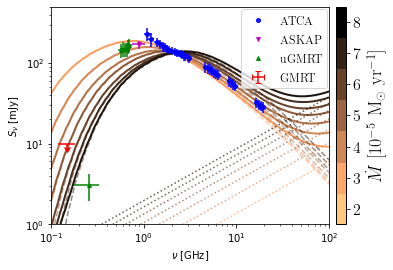

In [10]:
# Voy a graficar datos y modelo
fig, ax = plt.subplots(1)

# Defino una paleta discreta
n = len(Mdots)
color_vector = np.linspace(0.2,0.9,n)
colors = plt.cm.copper_r(color_vector) # define a palette avoiding extreme colors
# Genero una colorbar discreta para n puntos
c = np.arange(1, n+1) 
cmap = plt.cm.get_cmap('copper_r', n)
norm = matplotlib.colors.BoundaryNorm(np.arange(n+1)+0.5,n)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# Definiciones estéticas
nice_fonts = {
        # Use LaTeX to write all text
        "text.usetex": True,
        "font.family": 'serif',
        # Use 10pt font in plots, to match 10pt font in document
        "axes.labelsize": 18,
        "font.size": 18,
        "axes.linewidth":1,
        "axes.titlesize":16,
        # Make the legend/label fonts a little smaller
        "legend.fontsize": 12,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "xtick.major.size": 5,     # major tick size in points
        "xtick.minor.size": 5,       # minor tick size in points
        "xtick.major.width": 1.4,     # major tick width in points
        "xtick.minor.width": 1.4,     # minor tick width in points
}
matplotlib.rcParams.update(nice_fonts)

# Set labels
plt.setp(ax, xlabel=r"$\nu$ [GHz]")
plt.setp(ax, ylabel=r"$S_\nu$ [mJy]")

# Definiciones generales
plt.title('')
plt.xlim(1e-1, 1e2)
plt.ylim(1e0, 5e2)

# Grafico las funciones individuales y su suma usando una paleta discreta
for i in range(n):
    plt.plot(SEDs_syn[i][0], SEDs_tot[i], ls='-', color=colors[i], linewidth=2, label='', zorder=1)
    plt.plot(SEDs_syn[i][0], SEDs_syn[i][1], ls='--', color=colors[i], alpha=0.5, label='', zorder=1)
    plt.plot(SEDs_ff[i][:,0], SEDs_ff[i][:,1], ls=':', color=colors[i], alpha=0.7, label='', zorder=1)

# Grafico cada set de datos y sus barras de error
#plt.errorbar(nu_C2019, flux_C2019, yerr=flux_C2019_err, xerr=nu_C2019_err, hold=True, ecolor='b', alpha=1, fmt='none', zorder=2)
#plt.plot(nu_C2019, flux_C2019, 'bo', alpha=0.9, label = 'ATCA', zorder=2)
plt.errorbar(nu_ATCA, flux_ATCA, yerr=flux_ATCA_err, xerr=nu_ATCA_err, hold=True, ecolor='b', alpha=1, fmt='none', zorder=2)
plt.plot(nu_ATCA, flux_ATCA, 'bo', alpha=0.9, label = 'ATCA', zorder=2, ms=4)

plt.errorbar(nu_askap, flux_askap, yerr=flux_askap_err, xerr=nu_askap_err, hold=True, ecolor='m', alpha=1, fmt='none', zorder=2)
plt.plot(nu_askap, flux_askap, 'mv', alpha=0.9, label = 'ASKAP', zorder=2, ms=4)

plt.errorbar(nu_ugmrt, flux_ugmrt, yerr=flux_ugmrt_err, xerr=nu_ugmrt_err, hold=True, ecolor='g', alpha=1, fmt='none', zorder=2)
plt.plot(nu_ugmrt, flux_ugmrt, 'g^', alpha=0.9, label = 'uGMRT', zorder=2, ms=4)

#plt.errorbar(nu_most, flux_most, yerr=flux_most_err, xerr=nu_most_err, hold=True, ecolor='g', alpha=1, fmt='none', zorder=2)
#plt.plot(nu_most, flux_most, 'yo', alpha=0.9, label = 'MOST', zorder=2)

plt.errorbar(nu_gmrt, flux_gmrt, yerr=flux_gmrt_err, xerr=nu_gmrt_err, uplims=flux_gmrt, hold=True, ecolor='r', alpha=1, fmt='none', label='GMRT', zorder=2)


plt.legend(loc='upper right', bbox_to_anchor=(1.015, 1.015))
ax.loglog() 

cbar = fig.colorbar(sm, ticks=c, label=r"$\dot{M}$ [$10^{-5}$ M$_\odot$ yr$^{-1}$]", pad=0.02)
cbar.ax.set_yticklabels(Mdots)  # vertically oriented colorbar

plt.show()

In [11]:
fig.savefig('SEDs_Mdot.pdf', bbox_inches='tight', pad_inches = 0)

In [23]:
SED_eta_low = read_SED('radsyn_WCR_eta0.44.dat')
SED_eta_high = read_SED('radsyn_WCR_eta0.52.dat')

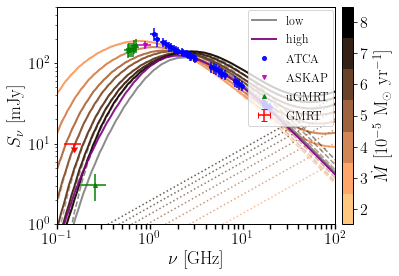

In [24]:
# Voy a graficar datos y modelo
fig, ax = plt.subplots(1)

# Defino una paleta discreta
n = len(Mdots)
color_vector = np.linspace(0.2,0.9,n)
colors = plt.cm.copper_r(color_vector) # define a palette avoiding extreme colors
# Genero una colorbar discreta para n puntos
c = np.arange(1, n+1) 
cmap = plt.cm.get_cmap('copper_r', n)
norm = matplotlib.colors.BoundaryNorm(np.arange(n+1)+0.5,n)
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)

# Definiciones estéticas
nice_fonts = {
        # Use LaTeX to write all text
        "text.usetex": True,
        "font.family": 'serif',
        # Use 10pt font in plots, to match 10pt font in document
        "axes.labelsize": 18,
        "font.size": 18,
        "axes.linewidth":1,
        "axes.titlesize":16,
        # Make the legend/label fonts a little smaller
        "legend.fontsize": 12,
        "xtick.labelsize": 16,
        "ytick.labelsize": 16,
        "xtick.major.size": 5,     # major tick size in points
        "xtick.minor.size": 5,       # minor tick size in points
        "xtick.major.width": 1.4,     # major tick width in points
        "xtick.minor.width": 1.4,     # minor tick width in points
}
matplotlib.rcParams.update(nice_fonts)

# Set labels
plt.setp(ax, xlabel=r"$\nu$ [GHz]")
plt.setp(ax, ylabel=r"$S_\nu$ [mJy]")

# Definiciones generales
plt.title('')
plt.xlim(1e-1, 1e2)
plt.ylim(1e0, 5e2)

# Grafico las funciones individuales y su suma usando una paleta discreta
for i in range(n):
    plt.plot(SEDs_syn[i][0], SEDs_tot[i], ls='-', color=colors[i], linewidth=2, label='', zorder=1)
    plt.plot(SEDs_syn[i][0], SEDs_syn[i][1], ls='--', color=colors[i], alpha=0.5, label='', zorder=1)
    plt.plot(SEDs_ff[i][:,0], SEDs_ff[i][:,1], ls=':', color=colors[i], alpha=0.7, label='', zorder=1)

plt.plot(SED_eta_low[0], SED_eta_low[1], ls='-', linewidth=2, color='grey', alpha=0.9, label='low', zorder=1)
plt.plot(SED_eta_high[0], SED_eta_high[1], ls='-', linewidth=2, color='purple', alpha=0.9, label='high', zorder=1)
# Grafico cada set de datos y sus barras de error
#plt.errorbar(nu_C2019, flux_C2019, yerr=flux_C2019_err, xerr=nu_C2019_err, hold=True, ecolor='b', alpha=1, fmt='none', zorder=2)
#plt.plot(nu_C2019, flux_C2019, 'bo', alpha=0.9, label = 'ATCA', zorder=2)
plt.errorbar(nu_ATCA, flux_ATCA, yerr=flux_ATCA_err, xerr=nu_ATCA_err, hold=True, ecolor='b', alpha=1, fmt='none', zorder=2)
plt.plot(nu_ATCA, flux_ATCA, 'bo', alpha=0.9, label = 'ATCA', zorder=2, ms=4)

plt.errorbar(nu_askap, flux_askap, yerr=flux_askap_err, xerr=nu_askap_err, hold=True, ecolor='m', alpha=1, fmt='none', zorder=2)
plt.plot(nu_askap, flux_askap, 'mv', alpha=0.9, label = 'ASKAP', zorder=2, ms=4)

plt.errorbar(nu_ugmrt, flux_ugmrt, yerr=flux_ugmrt_err, xerr=nu_ugmrt_err, hold=True, ecolor='g', alpha=1, fmt='none', zorder=2)
plt.plot(nu_ugmrt, flux_ugmrt, 'g^', alpha=0.9, label = 'uGMRT', zorder=2, ms=4)

#plt.errorbar(nu_most, flux_most, yerr=flux_most_err, xerr=nu_most_err, hold=True, ecolor='g', alpha=1, fmt='none', zorder=2)
#plt.plot(nu_most, flux_most, 'yo', alpha=0.9, label = 'MOST', zorder=2)

plt.errorbar(nu_gmrt, flux_gmrt, yerr=flux_gmrt_err, xerr=nu_gmrt_err, uplims=flux_gmrt, hold=True, ecolor='r', alpha=1, fmt='none', label='GMRT', zorder=2)


plt.legend(loc='upper right', bbox_to_anchor=(1.015, 1.015))
ax.loglog() 

cbar = fig.colorbar(sm, ticks=c, label=r"$\dot{M}$ [$10^{-5}$ M$_\odot$ yr$^{-1}$]", pad=0.02)
cbar.ax.set_yticklabels(Mdots)  # vertically oriented colorbar

plt.show()